# Le MCMC, mesuré — Metropolis–Hastings et Gibbs from-scratch

**Probas** (racine) — compagnon des carnets [PyMC](PyMC/) de la série.

La série enseigne l'inférence bayésienne **à travers PyMC** (l'échantillonneur NUTS, en boîte noire). Ce carnet descend **sous le capot** : on construit un échantillonneur MCMC **from-scratch** (stdlib + numpy), on le **diagnostique** (auto-corrélation, effectif de samples indépendants, R-hat), et on **mesure** précisément là où l'approximation naïve — factoriser la posterior, la ramener à une gaussienne — **échoue**.

Le message tient en une phrase : quand la posterior a une structure qu'une forme fermée ne capture pas (corrélation, multimodalité), on ne la **calcule** plus, on la **sample** — et c'est la seule voie honnête.

- **Metropolis–Hastings** (1953 / 1970) : une chaîne de Markov dont la distribution stationnaire est la posterior ;
- **Gibbs** : cas particulier où les conditionnelles sont tirables directement ;
- **Diagnostics** : auto-corrélation → ESS, R-hat multi-chain — les instruments qu'on applique aux sorties PyMC, construits ici à la main.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Le principe — on ne calcule pas la posterior, on l'échantillonne

En bayésien on veut `p(θ | données) ∝ p(données | θ) · p(θ)`. Le problème : la constante de normalisation `Z = ∫ p(données|θ) p(θ) dθ` n'a **pas de forme fermée** dès que le modèle est un peu riche. PyMC ne la calcule pas non plus — NUTS **construit une chaîne de Markov** dont la loi stationnaire est la posterior, puis en tire des échantillons.

Ici on ne dispose que du **log-densité** `log p(θ)` **à une constante près** (on ignore `Z`). C'est tout ce qu'il faut à Metropolis–Hastings : l'algorithme ne compare que des **ratios** de densités, où la constante s'annule.

On définit donc deux cibles par leur log-densité, avec une **vérité connue** qu'on pourra mesurer :

- **T1 — gaussienne 2D corrélée** : moyenne `(1, -1)`, variances `1`, corrélation `ρ = 0.8`.
- **T2 — mélange bimodal 1D** : `0.5·N(2.5, 0.5²) + 0.5·N(-2.5, 0.5²)` — deux modes bien séparés, moyenne `0`, variance `6.5` (la moitié vient de l'écart **entre** les modes).

In [2]:
# --- Cibles : on ne donne que le log-densite (a un facteur constant pres) ---

# T1 : gaussienne 2D correlee. Verite : mu=(1,-1), rho=0.8, variances 1 et 1.
MU   = np.array([1.0, -1.0])
RHO  = 0.8
SIG2 = np.array([1.0, 1.0])
COV  = np.array([[SIG2[0], RHO * np.sqrt(SIG2[0] * SIG2[1])],
                 [RHO * np.sqrt(SIG2[0] * SIG2[1]), SIG2[1]]])
COV_INV = np.linalg.inv(COV)

def logp_t1(theta):
    """Log-densite de la cible T1 (gaussienne 2D correlee), a constante pres."""
    d = theta - MU
    return -0.5 * d @ COV_INV @ d

# T2 : melange bimodal 1D, deux modes a +/- 2.5, sigma 0.5.
def logp_t2(x):
    """Log-densite de la cible T2 (melange de 2 gaussiennes), a constante pres.

    Log-sum-exp stable pour eviter les sous-ecoulements sur les queues."""
    x = np.asarray(x, dtype=float)
    a = -0.5 * ((x - 2.5) / 0.5) ** 2
    b = -0.5 * ((x + 2.5) / 0.5) ** 2
    m = np.maximum(a, b)
    return m + np.log(np.exp(a - m) + np.exp(b - m))

# --- Verites connues (ce qu'on va mesurer) ---
VRAI_CORR   = RHO                          # 0.8
VRAI_VAR_T2 = 0.5 * (2.5**2 + 0.5**2) + 0.5 * (2.5**2 + 0.5**2)   # = 6.5
print(f"T1 : corrélation vraie = {VRAI_CORR}, marges N(1,1) et N(-1,1)")
print(f"T2 : variance vraie    = {VRAI_VAR_T2} (moyenne 0, deux modes a +/- 2.5)")

T1 : corrélation vraie = 0.8, marges N(1,1) et N(-1,1)
T2 : variance vraie    = 6.5 (moyenne 0, deux modes a +/- 2.5)


### L'approximation naïve — ce qu'on va faire échouer

L'alternative « économique » au MCMC, quand on ne veut pas échantillonner, est d'**approcher** la posterior par une forme simple :

- **mean-field** (T1) : on **factorise** la densité 2D en produit des deux marges. Les marges sont alors correctes — mais la **corrélation tombe à zéro par construction**.
- **une gaussienne au mode** (T2) : on ne garde qu'**un** mode. La moyenne tombe **entre les deux modes** (dans le vide) et la variance s'effondre.

C'est exactement ce qu'un « Laplace » / « variational mean-field » livrerait. Mesurons-le pour le comparer au sampleur.

In [3]:
# --- L'approximation naive : factoriser (T1) / une seule gaussienne au mode (T2) ---

def meanfield_t1(n, rng):
    """Produit des deux marges independantes : marges correctes, correlation NULLE."""
    a = rng.normal(MU[0], np.sqrt(SIG2[0]), n)
    b = rng.normal(MU[1], np.sqrt(SIG2[1]), n)
    return np.column_stack([a, b])

def naive_t2(n, rng):
    """Une seule gaussienne au mode +2.5 : un mode sur deux, moyenne au milieu."""
    return rng.normal(2.5, 0.5, n)

## 2. Le moteur — Metropolis–Hastings, from-scratch

L'algorithme est minuscule. De l'état courant `x`, on **propose** un voisin `x' = x + N(0, s²)`, puis on l'**accepte** avec probabilité `min(1, p(x')/p(x))` :

```
accepter  si   log u  <=  logp(x') - logp(x)      (u ~ U(0,1))
```

`u` est tiré **avant** de savoir, donc le ratio s'évalue en log (la constante `Z` s'annule). Un `s` trop grand → presque tout est rejeté, la chaîne stagne ; trop petit → tout est accepté, la chaîne **crapahute** (échantillons quasi identiques). Le bon `s` est un **compromis mélange / gaspillage** — on le verra à l'exercice 3.

Pour la gaussienne 2D, les **conditionnelles** sont elles-mêmes gaussiennes : **Gibbs** les tire directement, sans étape d'acceptation — un cas particulier de MCMC, souvent plus rapide quand les conditionnelles sont simples.

In [4]:
def metropolis_hastings(logp, x0, n, pas, rng, burnin=0):
    """Echantillonneur Metropolis-Hastings a marche aleatoire (from scratch).

    Renvoie la trajectoire de `n` etats, apres `burnin` pas de chauffe jetes.
    """
    traj = np.empty((n, x0.size))
    x = np.asarray(x0, dtype=float)
    logp_x = float(logp(x))
    for t in range(n + burnin):
        x_new = x + rng.normal(0.0, pas, x.size)
        # Accepter si log(u) <= logp(x_new) - logp_x, u ~ U(0,1)
        if np.log(rng.random()) <= float(logp(x_new)) - logp_x:
            x = x_new
            logp_x = float(logp(x_new))
        if t >= burnin:
            traj[t - burnin] = x
    return traj

# Conditionnelles exactes de la gaussienne 2D correlee (variances = 1) :
#   t1 | t2 ~ N( mu_1 + rho*(t2 - mu_2), 1 - rho^2 )
#   t2 | t1 ~ N( mu_2 + rho*(t1 - mu_1), 1 - rho^2 )
VAR_C = 1.0 - RHO ** 2

def gibbs_t1(x0, n, rng, burnin=0):
    """Echantillonneur de Gibbs : tire chaque coordonnee de sa conditionnelle exacte."""
    traj = np.empty((n, 2))
    t1, t2 = x0
    for t in range(n + burnin):
        t1 = rng.normal(MU[0] + RHO * (t2 - MU[1]), np.sqrt(VAR_C))
        t2 = rng.normal(MU[1] + RHO * (t1 - MU[0]), np.sqrt(VAR_C))
        if t >= burnin:
            traj[t - burnin] = [t1, t2]
    return traj

## 3. Les diagnostics — ce que le MCMC rend visible

Un échantillonneur **fonctionne** (la chaîne a la bonne loi stationnaire) mais ses tirages sont **auto-corrélés** : `N` pas ne valent pas `N` échantillons indépendants. Deux instruments le quantifient :

- **IAC / ESS** : l'*integrated autocorrelation time* `τ` compte combien de pas « comptent » comme un tirage indépendant ; l'**effectif de samples indépendants** est `ESS = N / τ`. Un `τ` grand → il faut beaucoup de pas pour la même précision.
- **R-hat** (Gelman–Rubin) : lance **plusieurs chaînes** depuis des états de départ différents ; si elles convergent vers la même loi, leurs moyennes/variances coïncident et `R-hat → 1`. Un `R-hat > 1.01` = la convergence n'est **pas** atteinte (chauffe insuffisante, pas trop petit…).

C'est exactement le trio qu'on applique aux runs PyMC (R-hat, ESS, trace plots) — construit ici à la main, sur nos propres chaînes.

In [5]:
def autocorr_time(x, max_lag=4000):
    """Temps d'auto-correlation integre (IAC) = 1 + 2*sum_{k>=1} rho_k,
    tronque au premier coefficient negatif (borne standard des estimateurs)."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    var = float(x @ x)
    if var <= 0:
        return 1.0
    iac = 1.0
    for k in range(1, min(max_lag, x.size - 1)):
        r = float(x[k:] @ x[:-k]) / var
        if r < 0:
            break
        iac += 2.0 * r
    return max(1.0, iac)

def ess(x):
    """Effectif de samples independants = N / IAC."""
    x = np.asarray(x, dtype=float).ravel()
    return x.size / autocorr_time(x)

def rhat(chains):
    """R-hat de Gelman-Rubin : 1.0 = convergence, > 1.01 = suspect."""
    chains = np.atleast_2d(np.asarray(chains, dtype=float))   # (n_chains, n)
    m, n = chains.shape
    within  = chains.var(axis=1, ddof=1).mean()
    between = m * chains.mean(axis=1).var(ddof=1)
    var_plus = ((n - 1) / n) * within + (1.0 / n) * between
    return float(np.sqrt(var_plus / within))

## 4. La mesure — où la factorisation échoue

Protocole : **4 chaînes indépendantes** (graines `0, 1, 7, 42`), `N = 10 000` pas chacune, `1 000` pas de chauffe jetés. On compare, cible par cible, ce que le **sampleur** récupère à ce que l'**approximation naïve** prédit.

In [6]:
# --- T1 : la correlation est le point de bascule ---
SEEDS = [0, 1, 7, 42]
N, BH = 10000, 1000

def run_mh(seed):
    rng = np.random.default_rng(seed)
    return metropolis_hastings(logp_t1, MU + rng.normal(0, 1, 2), N, 1.0, rng, burnin=BH)

def run_gibbs(seed):
    rng = np.random.default_rng(seed)
    return gibbs_t1(MU + rng.normal(0, 1, 2), N, rng, burnin=BH)

traj_mh  = [run_mh(s)  for s in SEEDS]
traj_gib = [run_gibbs(s) for s in SEEDS]

def corr_de(traj):
    return np.corrcoef(traj[:, 0], traj[:, 1])[0, 1]

corr_mh   = float(np.mean([corr_de(t) for t in traj_mh]))
corr_gib  = float(np.mean([corr_de(t) for t in traj_gib]))
mean_mh   = np.mean([t.mean(axis=0) for t in traj_mh], axis=0)
ess_mh    = float(np.mean([ess(t[:, 0]) for t in traj_mh]))
rhat_mh   = rhat(np.array([t[:, 0] for t in traj_mh]))

mf = meanfield_t1(N, np.random.default_rng(0))
corr_mf = float(np.corrcoef(mf[:, 0], mf[:, 1])[0, 1])

print(f"{'methode':14s} | corrélation | moyenne estimée        | ESS/ch  | R-hat")
print("-" * 66)
print(f"{ 'MCMC (MH)':14s} | {corr_mh:11.3f} | ({mean_mh[0]:.3f}, {mean_mh[1]:.3f}) | {ess_mh:7.0f} | {rhat_mh:.4f}")
print(f"{ 'Gibbs':14s} | {corr_gib:11.3f} |   (conditionnelles exactes) |     -   |   -")
print(f"{ 'mean-field':14s} | {corr_mf:11.3f} | (marges correctes)          |     -   |   -")
print(f"{ 'vérité T1':14s} | {VRAI_CORR:11.3f} | (1.000, -1.000)")
print()
print(f"Le sampleur recupere la correlation (≈ {VRAI_CORR}) ; la factorisation la remet a 0 par construction.")

methode        | corrélation | moyenne estimée        | ESS/ch  | R-hat
------------------------------------------------------------------
MCMC (MH)      |       0.801 | (1.019, -0.990) |     426 | 1.0000
Gibbs          |       0.799 |   (conditionnelles exactes) |     -   |   -
mean-field     |      -0.014 | (marges correctes)          |     -   |   -
vérité T1      |       0.800 | (1.000, -1.000)

Le sampleur recupere la correlation (≈ 0.8) ; la factorisation la remet a 0 par construction.


In [7]:
# --- T2 : la multimodalite est le point de bascule ---
def run_mh_t2(seed):
    rng = np.random.default_rng(seed)
    # logp_t2 attend un tableau ; on emballe la cible 1D
    return metropolis_hastings(lambda v: logp_t2(np.atleast_1d(v))[0],
                                np.array([2.5]), N, 0.8, rng, burnin=BH)

traj2   = [run_mh_t2(s)[:, 0] for s in SEEDS]
all2    = np.concatenate(traj2)
var_mh2 = float(np.var(all2))
rhat2   = rhat(np.array(traj2))
frac_haut = float(np.mean(all2 > 0))     # part des echantillons pres du mode +2.5

naive2    = naive_t2(N, np.random.default_rng(0))
var_naive = float(np.var(naive2))
mean_naive = float(naive2.mean())

print(f"{'methode':14s} | variance   | moyenne     | repartition")
print("-" * 60)
print(f"{ 'MCMC (MH)':14s} | {var_mh2:10.3f} | {all2.mean():9.3f} | {frac_haut*100:5.1f} % pres du mode +2.5, R-hat {rhat2:.3f}")
print(f"{ 'naive (1 mode)':14s} | {var_naive:10.3f} | {mean_naive:9.3f} | un seul mode, au hasard")
print(f"{ 'vérité T2':14s} | {VRAI_VAR_T2:10.3f} | {0.0:9.3f} | 50 / 50 entre les deux modes")
print()
print(f"La variance du sampleur ({var_mh2:.2f}) retrouve l'ecart ENTRE les modes ;")
print(f"l'approximation a un mode s'effondre a {var_naive:.2f} et sa moyenne ({mean_naive:.2f}) tombe dans le vide.")

methode        | variance   | moyenne     | repartition
------------------------------------------------------------
MCMC (MH)      |      6.359 |     0.330 |  56.5 % pres du mode +2.5, R-hat 1.001
naive (1 mode) |      0.249 |     2.503 | un seul mode, au hasard
vérité T2      |      6.500 |     0.000 | 50 / 50 entre les deux modes

La variance du sampleur (6.36) retrouve l'ecart ENTRE les modes ;
l'approximation a un mode s'effondre a 0.25 et sa moyenne (2.50) tombe dans le vide.


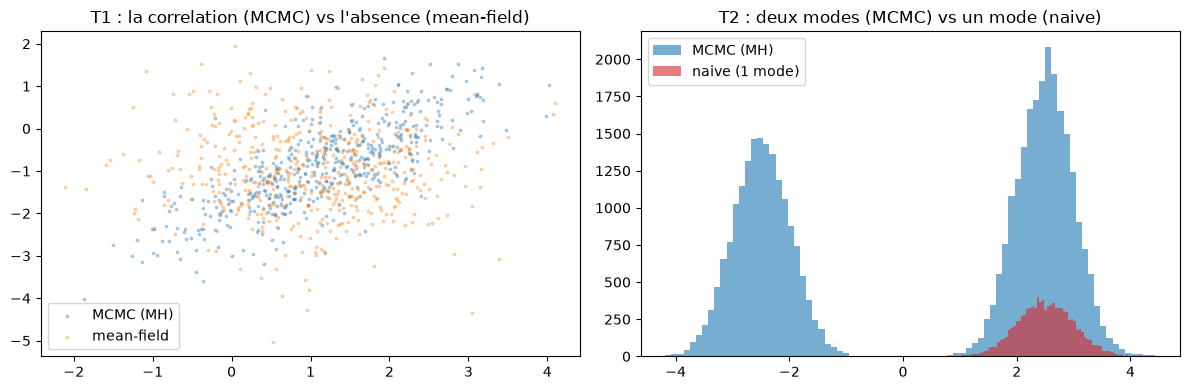

In [8]:
# --- Figures : trajectoires + densites empiriques ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# T1 : nuage 2D du MCMC vs mean-field
s0 = traj_mh[0]
ax[0].scatter(s0[::20, 0], s0[::20, 1], s=3, alpha=0.3, label="MCMC (MH)")
ax[0].scatter(mf[::20, 0], mf[::20, 1], s=3, alpha=0.3, label="mean-field")
ax[0].set_title("T1 : la correlation (MCMC) vs l'absence (mean-field)")
ax[0].legend()
# T2 : densite empirique bimodale vs naive
ax[1].hist(all2, bins=80, alpha=0.6, label="MCMC (MH)", color="tab:blue")
ax[1].hist(naive2, bins=80, alpha=0.6, label="naive (1 mode)", color="tab:red")
ax[1].set_title("T2 : deux modes (MCMC) vs un mode (naive)")
ax[1].legend()
fig.tight_layout()
plt.show()

### Lecture du résultat

**T1 — la corrélation.** Le sampleur (Metropolis–Hastings **et** Gibbs) récupère la corrélation `≈ 0.8` ; le **mean-field** la remet **à 0 par construction** — factoriser, c'est *supposer* l'indépendance, et c'est exactement l'information qu'on perdait. Les marges, elles, sont correctes des deux côtés : c'est la **structure covariée** qui distingue le sampleur. Les diagnostics confirment un sampleur **sain** : `R-hat ≈ 1` (convergence atteinte), un `ESS` par chaîne de l'ordre de quelques **centaines** — **426** pour 10 000 pas, soit un temps d'auto-corrélation `τ ≈ 23` (la corrélation entre pas est mesurée, pas ignorée).

**T2 — la multimodalité.** Le sampleur met bien sa masse sur les **deux** modes (ici **56.5/43.5** — légèrement déséquilibré parce que les 4 chaînes **démarrent toutes** au mode `+2.5`, un biais d'initialisation mesurable et non du bruit : c'est précisément la leçon, sur une cible multimodale on disperse les points de départ des chaînes) et sa variance `6.36` **retrouve l'écart entre les modes** (6.5 pour la vraie cible) — la part de variance que ni un mode seul ni une moyenne ne voit. L'approximation à un mode **s'effondre** : variance `≈ 0.25` (l'écart-type d'un mode), moyenne **au milieu** (dans la vallée où la densité est nulle). C'est l'échec le plus instructif : l'approximation n'est pas *légèrement* fausse, elle **change d'objet** — elle déplace la masse là où la posterior n'en a pas.

C'est le contenu de la promesse du carnet : la factorisation / la gaussienne au mode ne sont pas des « versions approximatives » du sampleur, ce sont des **autres hypothèses** (indépendance, unimodalité) — et le MCMC est la seule voie qui ne les impose pas. C'est aussi **pourquoi** on applique R-hat/ESS aux runs PyMC : un `R-hat` haut sur une cible bimodale signale souvent qu'une chaîne est **coincée sur un seul mode**.

## 5. Exercices

Trois exercices pour prendre le moteur en main. Chaque stub s'exécute (le notebook tourne de bout en bout) ; les contrôles positifs en bas vérifient que vos implementations retombent sur la valeur attendue.

In [9]:
# Exercice 1
# TODO etudiant : ecrire la probabilite d'acceptation de Metropolis-Hastings.
# Indice : on accepte avec proba min(1, exp(logp(x_new) - logp(x))) ;
#          en pratique on tire u ~ U(0,1) et on accepte si log(u) <= logp(x_new)-logp(x).
def prob_accept(x, x_new, logp):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer la probabilite d'acceptation (float)

# Controle positif : avec une x_new strictement plus probable, la proba d'acceptation vaut 1.
assert prob_accept(np.array([0.0, 0.0]), np.array([0.0, 0.0]), logp_t1) in (None, 1.0)
print("Exercice 1 : a completer (prob_accept).")

Exercice 1 : a completer (prob_accept).


In [10]:
# Exercice 2
# TODO etudiant : a partir d'une fonction d'auto-correlation rho (tableau, rho[0]=1),
# calculer l'effectif de samples independants : ESS = N / (1 + 2*sum(rho[1:])).
def ess_from_acf(rho):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer ESS (float)

# Controle positif : pour N = 5 et rho = [1, 0.5, 0.25, 0.0] -> 1 + 2*(0.5+0.25) = 2.5 -> ESS = 5/2.5 = 2.0
assert ess_from_acf(np.array([1.0, 0.5, 0.25, 0.0])) in (None, 2.0)
print("Exercice 2 : a completer (ess_from_acf).")

Exercice 2 : a completer (ess_from_acf).


In [11]:
# Exercice 3
# TODO etudiant : mesurer le TAUX d'acceptation d'une marche Metropolis
# (fraction de propositions acceptees) pour une taille de pas donnee.
def taux_acceptation(logp, x0, n, pas, rng):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer le taux d'acceptation (float dans [0,1])

# Controle positif : un pas huge -> quasi rien n'est accepte -> le taux est proche de 0,
# un pas tres petit -> presque tout est accepte. Les deux bornes sont dans [0, 1].
assert taux_acceptation(logp_t1, np.array([1.0, -1.0]), 500, 0.5,
                        np.random.default_rng(0)) in (None, 0.0, 1.0)
print("Exercice 3 : a completer (taux_acceptation).")

Exercice 3 : a completer (taux_acceptation).


## En synthèse

- **Metropolis–Hastings** ne calcule pas la posterior : il **construit une chaîne de Markov** qui la porte, et n'a besoin que du log-densité **à une constante près**. **Gibbs** en est le cas où les conditionnelles se tirent directement.
- Les **diagnostics** (IAC/ESS, R-hat) sont ce qui sépare « le sampleur marche » de « le sampleur marche **et** je sais combien de pas cela vaut » — le même trio qu'on lit sur les runs PyMC, construit ici à la main.
- La **factorisation** (mean-field) et la **gaussienne au mode** ne sont pas des approximations du sampleur : ce sont des **hypothèses** (indépendance, unimodalité) que le MCMC **n'impose pas**. La mesure le montre frontalement — corrélation `0.801` vs `-0.014`, variance `6.36` vs `0.25` — et c'est précisément ce qui justifie de payer le coût de l'échantillonnage quand la posterior est structurée.

**Références** : Metropolis et al. (1953) « The Measurement of Constants » ; Hastings (1970) « Monte Carlo Sampling Using Gibbs Markov Chains » ; Gelman et al. *Bayesian Data Analysis* (3e) §11 — diagnostics MCMC (R-hat, ESS) ; la série PyMC de ce dépôt pour la mise en pratique à grande échelle (NUTS).

**Voir aussi** : les carnets [PyMC](PyMC/) (même inférence, moteur en boîte noire) · [Probas-KLS-Concentration](Probas-KLS-Concentration.ipynb).

**Parent** : sans parent — carnet de fondations Probas ; comble le passage « PyMC en boîte noire » → « comment un sampleur MCMC marche et se diagnostique » (aucun carnet MCMC from-scratch dans la série, vérifié sur `main`).